### Loading Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

### Preparing Data

In [2]:
#Loading Data
df = pd.read_csv('marketing_campaign.csv', sep='\t')
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [3]:
#Basic Checks
print(f"Shape: {df.shape}")
print(f"Columns: {df.columns}")

Shape: (2240, 29)
Columns: Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response'],
      dtype='str')


In [4]:
#Null Check
print(df.isnull().sum())
df["Income"] = df["Income"].fillna(df["Income"].median())

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64


### Cleaning and Standardizing

In [5]:
#Working on Date Columns
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], dayfirst=True, errors="coerce")
df["Customer_Tenure"] = (df["Dt_Customer"].max() - df["Dt_Customer"]).dt.days

#Removing Unwanted
df = df.drop(columns=["ID", "Dt_Customer", "Z_CostContact", "Z_Revenue", "Response"], errors="ignore")

#Separating and Standardizing Numerical and Categorical
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include="object").columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])
X = preprocessor.fit_transform(df)

print("Rows used:", X.shape[0])
print("Features after encoding:", X.shape[1])
print("Numerical features:", len(numeric_cols))
print("Categorical features:", categorical_cols)

Rows used: 2240
Features after encoding: 36
Numerical features: 23
Categorical features: ['Education', 'Marital_Status']


C:\Users\shaur\AppData\Local\Temp\ipykernel_22272\3219308972.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns.tolist()


### Find n_clusters using the Elbow Method

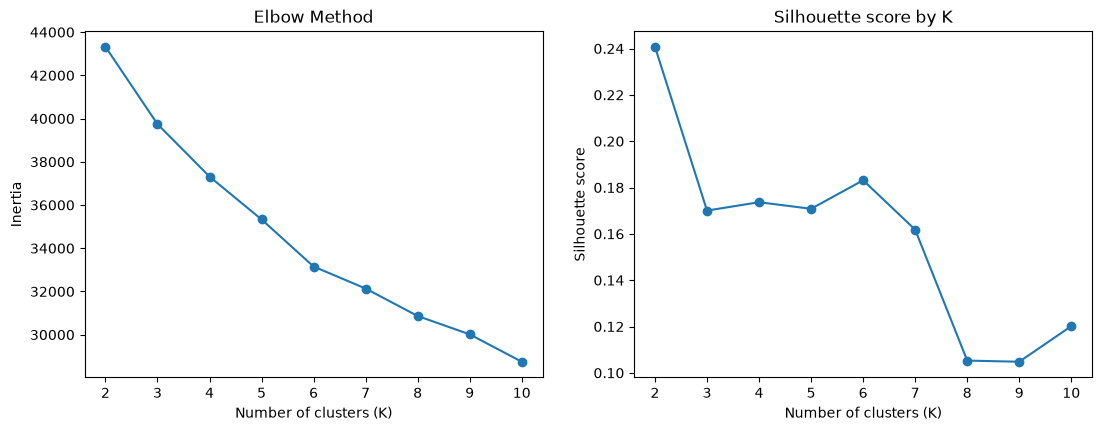

In [7]:
k_values = range(2, 11)
inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X)
    
    inertias.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

#Elbow Method
axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia")

#Silhouette Score
axes[1].plot(list(k_values), silhouette_scores, marker="o")
axes[1].set_title("Silhouette score by K")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette score")

plt.show()

### Training Model

In [8]:
#Training
kmeans = KMeans(n_clusters=4, random_state=42)
labels = kmeans.fit_predict(X)

print("Inertia:", round(kmeans.inertia_, 2))
print("Silhouette score:", round(silhouette_score(X, labels), 4))

df["Cluster"] = labels
print(df["Cluster"].value_counts().sort_index())

Inertia: 37434.96
Silhouette score: 0.1671
Cluster
0    1021
1     216
2     570
3     433
Name: count, dtype: int64


### Visualizing Separation

Explained variance ratio: [0.265 0.086]
Total variance shown in 2D: 35.08 %


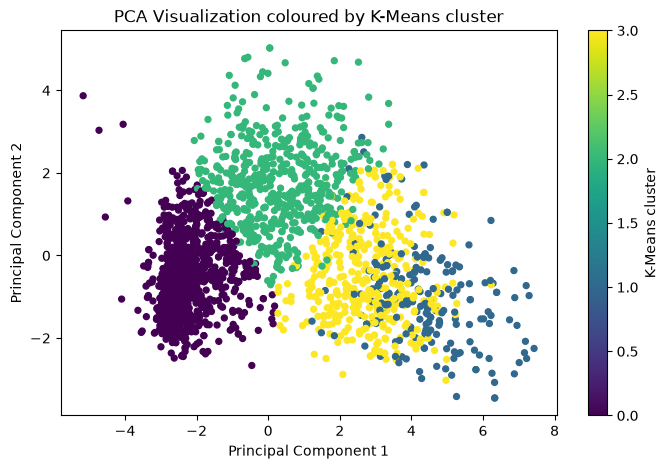

In [9]:
#Using PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

print("Explained variance ratio:", np.round(pca.explained_variance_ratio_, 3))
print("Total variance shown in 2D:", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

plt.figure(figsize=(8, 5))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, s=18)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization coloured by K-Means cluster")
plt.colorbar(scatter, label="K-Means cluster")
plt.show()

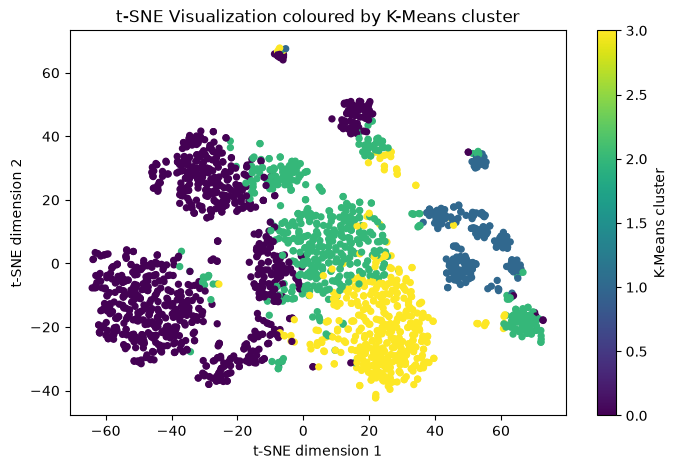

In [10]:
#Using TSNE
tsne = TSNE(n_components=2, perplexity=30, learning_rate="auto", init="pca", random_state=42)
X_tsne = tsne.fit_transform(X)

plt.figure(figsize=(8, 5))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=labels, s=18)
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.title("t-SNE Visualization coloured by K-Means cluster")
plt.colorbar(scatter, label="K-Means cluster")
plt.show()